# Milestone 1: football transfer playing time

**The question.** When a player joins a new club, predict his **league playing-time share** at that club in the
12 months after the transfer: his league minutes ÷ (90 × the club's league games), between 0 and 1.

This notebook follows the five parts of the milestone brief, plus the one clustering the proposal feedback asked
for. It runs top to bottom from a fresh clone: the first cell downloads any missing data, and the second builds
any missing tables with the project code in `src/` (notebooks 01–03 hold the detailed working behind each step).

In [2]:
# Download the raw data into data/raw/ (skips files you already have; ~250 MB on a fresh clone).
# Uses the pinned sources in src/data/download_data.py; raises DownloadError listing anything that failed.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data" / "download_data.py").is_file())
sys.path.insert(0, str(ROOT))
from src.data.download_data import download_all
download_all()

Wyscout -> /home/slage/Coding/Deep Learning/Project/Deep-Learning-Scouting/data/raw/wyscout
  players.json: already present, skipping
  teams.json: already present, skipping
  matches_*.json: already present, skipping
  events_*.json: already present, skipping
Transfermarkt -> /home/slage/Coding/Deep Learning/Project/Deep-Learning-Scouting/data/raw/transfermarkt
  players.csv.gz: already present, checksum OK, skipping
  transfers.csv.gz: already present, checksum OK, skipping
  appearances.csv.gz: already present, checksum OK, skipping
  games.csv.gz: already present, checksum OK, skipping
  clubs.csv.gz: already present, checksum OK, skipping
  player_valuations.csv.gz: already present, checksum OK, skipping
ClubElo -> /home/slage/Coding/Deep Learning/Project/Deep-Learning-Scouting/data/raw/clubelo
  EloRatings.csv: already present, checksum OK, skipping
Understat -> /home/slage/Coding/Deep Learning/Project/Deep-Learning-Scouting/data/raw/understat
  players_epl_14-15.csv: already pre

PosixPath('/home/slage/Coding/Deep Learning/Project/Deep-Learning-Scouting/data/raw')

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RepeatedKFold
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from src.pipelines import build_transfers as bt
from src.features import player_roles as pr
from src.models import baselines as bl
from src.data.transfermarkt import load_tables
from src.data.player_matching import club_agreement
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

OUT, RAW = ROOT / "data/processed", ROOT / "data/raw"
# Build anything missing: player features (~1 min) and the transfer dataset (~30 s).
if not all((OUT / f).exists() for f in ["transfers_joined.csv", "wyscout_tm_link.csv", "transfer_funnel.csv"]):
    bt.main()                                   # also builds player_features.csv if it's missing
pf = bt.load_player_features()                  # one row per Wyscout player, 2017/18
data = pd.read_csv(OUT / "transfers_joined.csv", parse_dates=["transfer_date"])
link = pd.read_csv(OUT / "wyscout_tm_link.csv")
funnel = pd.read_csv(OUT / "transfer_funnel.csv")
split = pd.read_csv(OUT / "split.csv", parse_dates=["transfer_date"])   # committed: the fixed split
tm = load_tables(RAW / "transfermarkt")         # for the match audit and the leakage demo

# Player roles (section 6), assigned with the k and anchors chosen in notebook 03 (decision D14)
roles = pr.assign_roles(pf, pr.K_BY_POSITION, pr.ROLE_ANCHORS)
data = data.merge(roles[["wy_id", "role"]], on="wy_id", how="left")
SEED = bt.SEED
print(f"{len(data)} transfers, {len(pf):,} Wyscout players, {len(roles):,} with a role")

276 transfers, 2,561 Wyscout players, 1,947 with a role


## 1 of 5 · The data

One row is **one transfer**. Five real rows:

In [5]:
show = ["player_name", "from_club_name", "to_club_name", "transfer_date", "position",
        "age", "log_mv", "prev_share_tm", "wy_share", "y"]
display(data[show].head(5).assign(transfer_date=lambda d: d.transfer_date.dt.date).round(3))

,player_name,from_club_name,to_club_name,transfer_date,position,age,log_mv,prev_share_tm,wy_share,y
0,Takuma Asano,Stuttgart,Arsenal,2018-06-30,Attack,23.636,14.509,0.235,0.235,0.000
1,Alex Meret,SPAL,Udinese,2018-06-30,Goalkeeper,21.273,16.300,0.339,0.339,0.000
2,Leonardo Spinazzola,Atalanta,Juventus,2018-06-30,Defender,25.265,16.300,0.441,0.440,0.175
3,Lorenzo Venuti,Benevento,Fiorentina,2018-06-30,Defender,23.217,14.221,0.698,0.697,0.000
4,Marco Sportiello,Fiorentina,Atalanta,2018-06-30,Goalkeeper,26.138,15.607,0.936,0.961,0.000


**How the rows were built (the funnel).** We built the data by joining two sources that use
different player ids, so the counts start from the Wyscout players and end at the transfers we can label.

In [4]:
w = funnel.step.str.len().max()
for s, n in zip(funnel.step, funnel.n):
    print(f"{s:<{w}}  {n:>7,}")
n_link = len(link)
print(f"\nPlayer matching: {n_link:,} of {len(pf):,} Wyscout players linked to Transfermarkt ({n_link / len(pf):.1%})")
print(link.match_pass.value_counts().to_string())
audit = club_agreement(pf, link, tm["players"], tm["appearances"], tm["clubs"])
print(f"Both sources agree on the player's main 2017/18 club for {audit.club_agree.mean():.1%} of matched players "
      "(most disagreements are January movers or names like 'PSG' vs 'Paris Saint-Germain')")

Wyscout players with 2017/18 league minutes    2,561
  linked to a Transfermarkt player             2,523
transfers of linked players (all years)       14,822
  dated 2018-05-15 to 2019-02-15                 795
  club-to-club moves                             791
  excluding loan returns                         522
  first move per player                          464
  destination club covered (>= 10 games)         358
  >= 450 Wyscout minutes  ->  FINAL              276

Player matching: 2,523 of 2,561 Wyscout players linked to Transfermarkt (98.5%)
match_pass
dob+name            2473
year+name+active      50
Both sources agree on the player's main 2017/18 club for 95.2% of matched players (most disagreements are January movers or names like 'PSG' vs 'Paris Saint-Germain')


**The label.** Our label is a number between 0 and 1, not a class, so instead of a label balance we show its
distribution. The constant-mean baseline's MSE is roughly this distribution's variance.

count    276.000
mean       0.489
std        0.290
min        0.000
25%        0.231
50%        0.533
75%        0.730
max        1.000

exactly 0 (never played): 5.4%   exactly 1 (every minute): 1.4%
variance of y: 0.0841


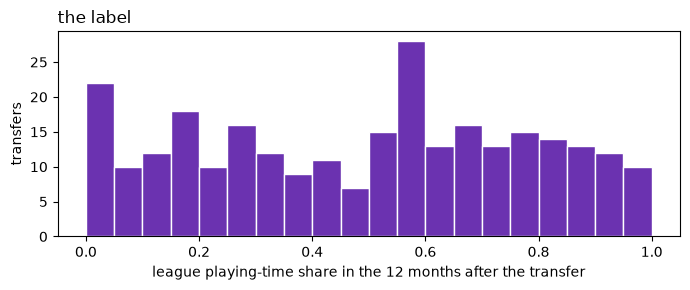

In [5]:
y = data.y
print(y.describe().round(3).to_string())
print(f"\nexactly 0 (never played): {(y == 0).mean():.1%}   exactly 1 (every minute): {(y == 1).mean():.1%}")
print(f"variance of y: {y.var(ddof=0):.4f}")
plt.figure(figsize=(7, 3))
plt.hist(y, bins=20, color="#6B32B0", edgecolor="white")
plt.xlabel("league playing-time share in the 12 months after the transfer"); plt.ylabel("transfers")
plt.title("the label", loc="left"); plt.tight_layout(); plt.show()

In [6]:
print("number of groups")
print(f"  players:            {data.player_id.nunique()}   (one transfer per player: we keep his first move)")
print(f"  destination clubs:  {data.to_club_id.nunique()}")
print(f"  selling clubs:      {data.from_club_id.nunique()}")

number of groups
  players:            276   (one transfer per player: we keep his first move)
  destination clubs:  111
  selling clubs:      100


## 2 of 5 · The split, and what we split **on**

**We split on the player.** Each player appears once (his first move in the window), so a player can never be on
both sides. The split is the fixed one in `data/processed/split.csv`, shared by every notebook and model; here we
rebuild it the same way and check it matches.

In [7]:
train_df, test_df = train_test_split(data, test_size=bt.TEST_SIZE, random_state=SEED)
check = bt.make_split(data).merge(split, on=bt.SPLIT_KEY, suffixes=("", "_saved"), validate="one_to_one")


print(f"train {len(train_df)}   test {len(test_df)}")
print(f"mean y in train {train_df.y.mean():.3f}, in test {test_df.y.mean():.3f}")
print("players on both sides:", len(set(train_df.player_id) & set(test_df.player_id)), "  <- this must be 0")
both = set(train_df.to_club_id) & set(test_df.to_club_id)
print(f"destination clubs on both sides: {len(both)} of {data.to_club_id.nunique()}; "
      f"{test_df.to_club_id.isin(both).mean():.0%} of test transfers go to a club that also appears in training")

train 220   test 56
mean y in train 0.484, in test 0.512
players on both sides: 0   <- this must be 0
destination clubs on both sides: 32 of 111; 80% of test transfers go to a club that also appears in training


**No player is on both sides.** Destination clubs do repeat: 32 of the 111 clubs appear on both sides, and 80% of
test transfers go to a club that is also in training.
- **Is that leakage?** No, our features don't include the club's identity, so the
  model can't "recognise the club" and overfit to it.
- **But those transfers are related.** Three strikers bought by one club compete for the same minutes. Splitting by
  destination club would be stricter. We keep the shared split and record this as a limitation.
- **Later:** in the multi-season dataset the same player can appear in several seasons, so that split must be by
  player **and** by time

### What a leaky feature would have given us

Our version of the "wrong split" is a **leaky feature**: information from *after* the transfer. A realistic mistake
is to use the player's market value **one year after** the move instead of the value at the move. Transfermarkt
raises the value of players who play a lot, so that column already contains part of the answer.

In [ ]:
P90 = [c for c in data.columns if c.endswith("_p90")]
NUM = ["age", "log_mv", "prev_share_tm", "wy_share", "pass_acc"] + P90
CAT = ["position"]

vals = tm["player_valuations"].dropna(subset=["date", "market_value_in_eur"]).sort_values("date")
def log_value_on(dates):
    """log market value on or before each date (merge_asof backward)."""
    q = data[["player_id"]].assign(date=dates).reset_index().sort_values("date")
    mv = pd.merge_asof(q, vals[["player_id", "date", "market_value_in_eur"]], on="date", by="player_id",
                       direction="backward").set_index("index")
    return np.log1p(mv.market_value_in_eur.reindex(data.index))
data["log_mv_1y_after"] = log_value_on(data.transfer_date + pd.Timedelta(days=365))   # LEAK: post-transfer
train_df, test_df = data.loc[train_df.index], data.loc[test_df.index]

cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)
NUM_LEAK = [c if c != "log_mv" else "log_mv_1y_after" for c in NUM]
leak = bl.evaluate({"value at the transfer (right)":   (bl.linear_regression(NUM, CAT), NUM + CAT),
                    "value 1 year after (leaky)":      (bl.linear_regression(NUM_LEAK, CAT), NUM_LEAK + CAT),
                    "always predict the average":      (bl.MeanBaseline(), NUM)},
                   train_df, test_df, cv)
display(leak[["cv_mse_mean", "test_mse"]].round(4))
print("Same data, model and split. Only one column changed.")

,cv_mse_mean,test_mse
model,,
value at the transfer (right),0.0865,0.1012
value 1 year after (leaky),0.0725,0.0697
always predict the average,0.0815,0.0973


Same data. Same model. Same split. Only one column changed.


**With the leaky column, the model comfortably "beats" the average:**
- test MSE **0.070** vs 0.097
- cross-validation 0.073 vs 0.082

It looks like a working model. That's the number that would have gone into a report, and it means nothing: a
player's market value a year later is partly a record of how much he played.

Every feature in our dataset is dated **on or before the transfer date** (`Plan.md` §4). Post-transfer columns are
kept only as diagnostics, never as model inputs.

## 3 of 5 · The model

The simplest model that could work: **linear regression** on the information a scout has at the transfer date.

- **Player:** age, log market value at the transfer, position.
- **Playing time before the move:** `prev_share_tm` (league share in the 365 days before, from Transfermarkt) and
  `wy_share` (share of his team's 2017/18 minutes, from Wyscout).
- **Performance in 2017/18 (Wyscout):** pass accuracy and nine per-90 counts (passes, key passes, assists, shots,
  goals, duels, duels won, interceptions, fouls).

Missing values get the training median plus a "was missing" flag; numbers are z-scored.

In [9]:
model = bl.linear_regression(NUM, CAT).fit(train_df[NUM + CAT], train_df.y)
n_params = bl.n_parameters(model)
print("model: linear regression")
print(f"inputs after preprocessing: {model[0].get_feature_names_out().size} "
      f"({len(NUM)} numbers, missing-value flags, {data.position.nunique()} position columns)")
print("trainable parameters:", n_params, f"  (for {len(train_df)} training rows, about 1 per {len(train_df) // n_params})")

model: linear regression
inputs after preprocessing: 19 (14 numbers, missing-value flags, 4 position columns)
trainable parameters: 20   (for 220 training rows, about 1 per 11)


## 4 of 5 · The error, and the baselines beside it

We picked the metric **before** training, in the proposal: **mean squared error (MSE)**.

In [10]:
METRIC = "MSE"
WHY = ("A large miss, like expecting a starter who then barely plays, costs a club far more than a small one, "
       "so errors are penalised by their square rather than counted equally.")
assert len(WHY.split()) >= 12
print(f"we report {METRIC}, because: {WHY}")

we report MSE, because: A large miss, like expecting a starter who then barely plays, costs a club far more than a small one, so errors are penalised by their square rather than counted equally.


Every model is scored the same way: **cross-validation on the 220 training transfers** (5 folds × 10 repeats;
mean ± spread across folds) and **once on the 56 test transfers**. MSE treats over- and underestimates the same,
but for a club **overestimating** playing time is the costly mistake (a signing who doesn't play), so the last
column counts test transfers whose prediction was at least 0.25 above what really happened.

The baselines:
- **always predict the average:** does no work.
- **plays as much as last year:** one rule, the lazy scout's guess (`prev_share_tm`; the average when unknown).
- **average for his role:** one rule using the role clustering of section 6.

In [11]:
results = bl.evaluate({"always predict the average":  (bl.MeanBaseline(), NUM),
                       "plays as much as last year":  (bl.PreviousShareBaseline(), ["prev_share_tm"]),
                       "average for his role":        (bl.GroupMeanBaseline("role"), ["role"]),
                       "linear regression":           (bl.linear_regression(NUM, CAT), NUM + CAT)},
                      train_df, test_df, cv)
display(results.round(4))

,cv_mse_mean,cv_mse_std,test_mse,test_rmse,overestimated by >= 0.25
model,,,,,
always predict the average,0.0815,0.0087,0.0973,0.3119,16 of 56
plays as much as last year,0.1458,0.0264,0.1533,0.3915,15 of 56
average for his role,0.0849,0.0109,0.1120,0.3347,14 of 56
linear regression,0.0865,0.0115,0.1012,0.3181,16 of 56


**Nothing beats always predicting the average.**
- **Cross-validation:** the average is best (0.0815 ± 0.0087). The role average (0.0849) and linear regression
  (0.0865) are slightly worse, within about one spread of it. "Plays as much as last year" is clearly the worst
  (0.146).
- **The test column says the same.**

Why:
1. **The data is small.** 220 training transfers for 20 parameters is enough to fit noise.
2. **The features describe the player alone.** Whether a signing plays depends just as much on the **club**:
   competition for his position, the manager, his price. None of that is in milestone 1.
3. **Last year's playing time doesn't carry over.** After a move, regulars at smaller clubs often become squad
   players at bigger ones, so the "last year" rule overestimates them, and it's the worst of the four.

We report this rather than hide it, because it sets the bar for the next milestones: **beat cross-validation MSE
0.0815 on this split.** The last column is similar for every model (14–16 of 56), so none of them avoids the
costly overestimates yet.

## 5 of 5 · Optimisation: two small checks

**The twenty-row check.** Train on 20 transfers and test on the same 20. If the model can't memorise 20 rows,
something is wired wrong. The 20 are spread across the whole range of y (not the first 20 rows), so the check
isn't run on one kind of transfer.

In [12]:
def memorise(n_rows):
    """Fit a fresh model on n_rows training transfers spread across the range of y; MSE on those same rows."""
    order = train_df.sort_values("y")
    rows = order.iloc[np.linspace(0, len(order) - 1, n_rows).round().astype(int)]
    m = bl.linear_regression(NUM, CAT).fit(rows[NUM + CAT], rows.y)
    return mean_squared_error(rows.y, m.predict(rows[NUM + CAT])), rows.y.var(ddof=0), bl.n_parameters(m)

mse20, var20, p20 = memorise(20)
print(f"twenty-row check: MSE on those same 20 = {mse20:.4f}  (their variance is {var20:.4f}, "
      f"so the model fits {1 - mse20 / var20:.0%} of it)")
mse15, _, p15 = memorise(15)
print(f"fifteen-row check: MSE on those same 15 = {mse15:.1e}  (~0: exact fit)")
print(f"\nWhy 20 rows isn't exactly 0: the model has {p20} parameters, but the position columns and the intercept "
      "overlap by one, so only 19 are independent, one fewer than 20 rows. With 15 rows (fewer than the parameters) "
      "it memorises them exactly. Either way, the wiring works and the data is readable.")

twenty-row check: MSE on those same 20 = 0.0077  (their variance is 0.0888, so the model fits 91% of it)
fifteen-row check: MSE on those same 15 = 3.1e-31  (~0: exact fit)

Why 20 rows isn't exactly 0: the model has 20 parameters, but the position columns and the intercept overlap by one, so only 19 are independent, one fewer than 20 rows. With 15 rows (fewer than the parameters) it memorises them exactly. Either way, the wiring works and the data is readable.


**The training curve.** Linear regression is normally solved in one step, so to see a curve we train the
same linear model step by step with stochastic gradient descent, on 70% of the training transfers, and watch the
MSE on those and on the other 30% (validation).

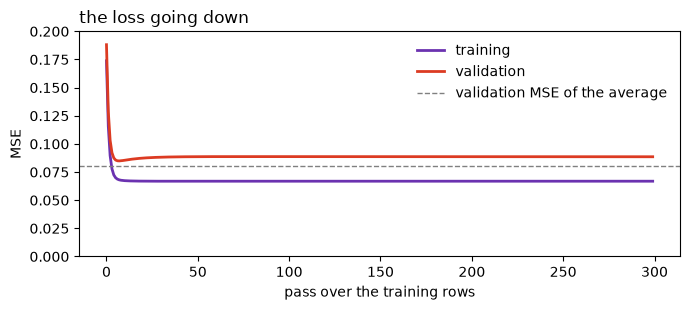

training MSE   0.174 -> 0.067
validation MSE 0.188 -> 0.089   (lowest 0.085 at pass 7)
validation MSE of always predicting the average: 0.080


In [13]:
tr2, va = train_test_split(train_df, test_size=0.3, random_state=0)
prep = bl.linear_regression(NUM, CAT)[0].fit(tr2[NUM + CAT])
X_tr, X_va = prep.transform(tr2[NUM + CAT]), prep.transform(va[NUM + CAT])
sgd = SGDRegressor(loss="squared_error", penalty=None, learning_rate="constant", eta0=0.002, random_state=0)
tr_loss, va_loss = [], []
for step in range(300):
    sgd.partial_fit(X_tr, tr2.y)
    tr_loss.append(mean_squared_error(tr2.y, sgd.predict(X_tr)))
    va_loss.append(mean_squared_error(va.y, sgd.predict(X_va)))
mean_va = mean_squared_error(va.y, np.full(len(va), tr2.y.mean()))

plt.figure(figsize=(7, 3.2))
plt.plot(tr_loss, label="training", color="#6B32B0", lw=2)
plt.plot(va_loss, label="validation", color="#DC3B22", lw=2)
plt.axhline(mean_va, color="grey", ls="--", lw=1, label="validation MSE of the average")
plt.xlabel("pass over the training rows"); plt.ylabel("MSE"); plt.ylim(0, max(0.2, mean_va * 1.6))
plt.legend(frameon=False); plt.title("the loss going down", loc="left"); plt.tight_layout(); plt.show()
print(f"training MSE   {tr_loss[0]:.3f} -> {tr_loss[-1]:.3f}")
print(f"validation MSE {va_loss[0]:.3f} -> {va_loss[-1]:.3f}   (lowest {min(va_loss):.3f} at pass {int(np.argmin(va_loss))})")
print(f"validation MSE of always predicting the average: {mean_va:.3f}")

**Training MSE keeps falling (0.174 → 0.067), but validation MSE is lowest after about 7 passes (0.085)**, then creeps up
to 0.089. It never gets below the average's 0.080.
- **The optimiser works:** the training loss goes down.
- **What it learns beyond the first few passes is specific to the training rows.** That's overfitting, the same
  story the table in section 4 tells.

## 6 · The one clustering: player roles

Players with ≥ 450 Wyscout minutes in 2017/18 are clustered **within each position** (k-means on 12 style features:
passing, progression, crosses, shots, dribbles, duels, interceptions, average position, width, final-third share).
k was chosen per position from bootstrap stability and whether the clusters can be named, and each role is named by
an anchor player (see `notebooks/03_player_roles.ipynb` and decision D14 in `Plan.md`).

In [14]:
display(roles.groupby(["position", "role"]).size().rename("players").to_frame())
check = ["Marcelo", "Sergio Ramos", "M. Hummels", "Sergio Busquets", "N. Kanté", "L. Modrić", "K. De Bruyne",
         "L. Messi", "Neymar", "H. Kane", "R. Lewandowski"]
fam = roles.merge(pf[["wy_id", "shortName", "wy_team"]], on="wy_id")
fam = fam[fam.shortName.isin(check) & ~((fam.shortName == "Marcelo") & (fam.wy_team != "Real Madrid"))]
display(fam.sort_values(["position", "role"])[["shortName", "wy_team", "position", "role"]].reset_index(drop=True))

players
position role                             
DF       Attacking full-back           154
         Ball-playing centre-back      151
         Defensive centre-back         217
         Defensive full-back           181
FW       Central striker               195
         Creative forward              100
         Wide support forward          108
GK       Goalkeeper                    135
MD       Attacking midfielder          153
         Ball-winning midfielder       189
         Deep-lying midfielder         182
         Wide midfielder               182

,shortName,wy_team,position,role
0,Marcelo,Real Madrid,DF,Attacking full-back
1,Sergio Ramos,Real Madrid,DF,Ball-playing centre-back
2,M. Hummels,Bayern München,DF,Ball-playing centre-back
3,H. Kane,Tottenham Hotspur,FW,Central striker
4,R. Lewandowski,Bayern München,FW,Central striker
5,L. Messi,Barcelona,FW,Creative forward
6,Neymar,PSG,FW,Creative forward
7,L. Modrić,Real Madrid,MD,Attacking midfielder
8,K. De Bruyne,Manchester City,MD,Attacking midfielder
9,Sergio Busquets,Barcelona,MD,Deep-lying midfielder


In [15]:
print("roles of the 276 transferred players, and their playing time after the move (descriptive only):")
display(data.groupby("role").y.agg(["count", "mean"]).sort_values("mean").round(3))

roles of the 276 transferred players, and their playing time after the move (descriptive only):


,count,mean
role,,
Attacking midfielder,20,0.366
Wide support forward,20,0.400
Defensive full-back,23,0.431
Attacking full-back,19,0.435
Wide midfielder,26,0.457
Creative forward,17,0.491
Ball-winning midfielder,36,0.504
Defensive centre-back,19,0.526
Ball-playing centre-back,19,0.538


**The roles look right:** famous players land where a scout would put them.

**One caveat:** per-90 counts partly reflect how much possession the player's **team** has, so Kanté shares the
deep-lying role with Busquets.

**After the move,** central strikers, goalkeepers and deep-lying midfielders played the most (about 0.55) and
attacking midfielders the least (0.37). With 17–36 transfers per role these differences are noisy, and the "average
for his role" row in section 4 shows that roles don't predict better than the overall average.

Roles become useful later, as the language for **team weaknesses** ("this squad lacks a ball-winning
midfielder").

## And one paragraph at the end

What worries us most is that, with 276 transfers and only player information, nothing we tried beats predicting the
average, so we can't yet show that the *fit* between player and team carries any signal. If that stays true, the
scouting idea doesn't work. In the next three weeks we will build a multi-season dataset (Transfermarkt with EA FC
player ratings: about 2,800 transfers instead of 276) with the same code in `src/`, and add the team side: team
style from Understat shot data, and team weaknesses expressed in our player roles. The first test is simple: do
player–team features beat cross-validation MSE 0.0815? If they don't, we will report it and keep the model small
rather than force a neural network onto noise.

In [16]:
best_base = results.drop(index="linear regression").cv_mse_mean.idxmin()
MILESTONE_1 = {
    "question":       "Predict a transferred player's league playing-time share in his first 12 months",
    "n_examples":     len(data),
    "n_groups":       f"{data.player_id.nunique()} players, {data.to_club_id.nunique()} destination clubs",
    "split_on":       "player (one transfer each); fixed split in data/processed/split.csv",
    "label_mean":     round(float(data.y.mean()), 3),
    "metric":         METRIC,
    "baseline_name":  "always predict the average",
    "baseline_score": round(float(results.loc["always predict the average", "test_mse"]), 4),
    "best_baseline":  f"{best_base} (cross-validation)",
    "model_name":     "linear regression on 14 pre-transfer numbers + position",
    "model_score":    round(float(results.loc["linear regression", "test_mse"]), 4),
    "biggest_worry":  "With 276 transfers and player-only features nothing beats the average; a fit signal may need more data and team features.",
}
for k, v in MILESTONE_1.items():
    print(f"{k:<16} {v}")

question         Predict a transferred player's league playing-time share in his first 12 months
n_examples       276
n_groups         276 players, 111 destination clubs
split_on         player (one transfer each); fixed split in data/processed/split.csv
label_mean       0.489
metric           MSE
baseline_name    always predict the average
baseline_score   0.0973
best_baseline    always predict the average (cross-validation)
model_name       linear regression on 14 pre-transfer numbers + position
model_score      0.1012
biggest_worry    With 276 transfers and player-only features nothing beats the average; a fit signal may need more data and team features.
